# Task 5 — Convolutional Neural Networks (CNNs)
**Machine Learning & Deep Learning Course Project**  
**Points: 10 pts**

---
**Dataset:** CIFAR-10 (10 classes, 60,000 images, 32×32×3 RGB)

We build:
1. A custom CNN from scratch (3 conv blocks + BN + Dropout)
2. Transfer learning with MobileNetV2
3. Filter + feature map visualizations

---

In [3]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
# ============================================================
#  IMPORTS
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings, time
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, LearningRateScheduler
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import classification_report, confusion_matrix

tf.random.set_seed(42)
np.random.seed(42)

print(f"TensorFlow: {tf.__version__}")
print(f"GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")
print("Imports successful ✓")

TensorFlow: 2.20.0
GPU available: True
Imports successful ✓


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Train: (45000, 32, 32, 3), Val: (5000, 32, 32, 3), Test: (10000, 32, 32, 3)
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


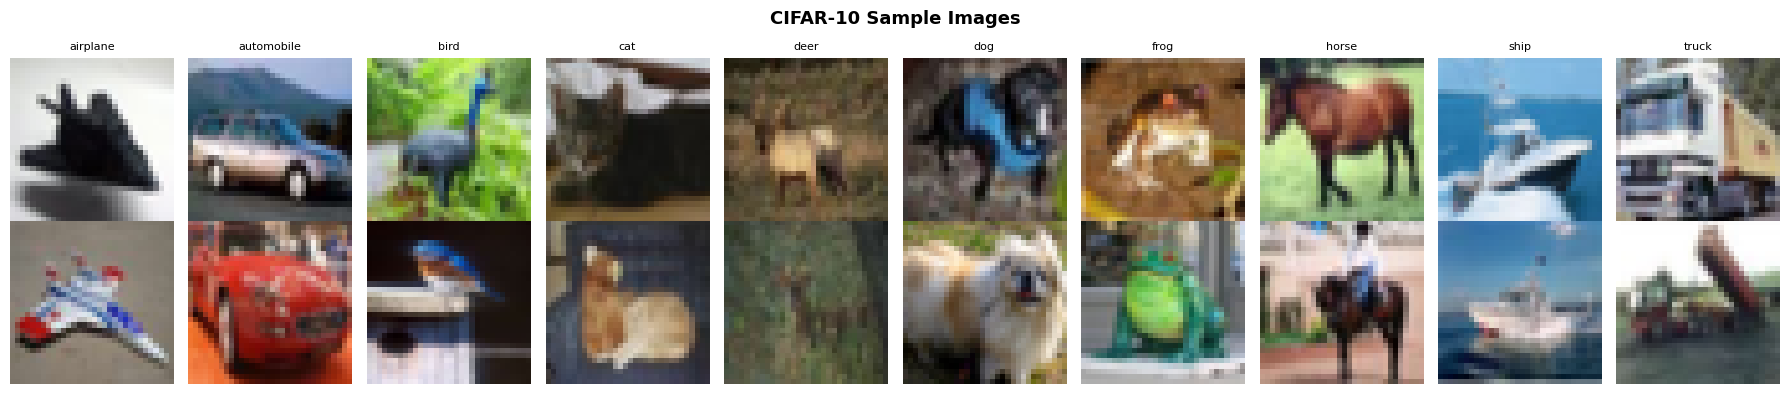

In [5]:
# ── Load CIFAR-10 ─────────────────────────────────────────
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = keras.datasets.cifar10.load_data()

CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Normalize pixel values to [0, 1]
X_train_raw = X_train_raw.astype('float32') / 255.0
X_test_raw  = X_test_raw.astype('float32') / 255.0

# Flatten labels
y_train_raw = y_train_raw.flatten()
y_test_raw  = y_test_raw.flatten()

# Use 10% for validation
val_size = 5000
X_val  = X_train_raw[-val_size:]
y_val  = y_train_raw[-val_size:]
X_train = X_train_raw[:-val_size]
y_train = y_train_raw[:-val_size]
X_test  = X_test_raw
y_test  = y_test_raw

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")
print(f"Classes: {CLASS_NAMES}")

# Visualize sample images
fig, axes = plt.subplots(2, 10, figsize=(18, 4))
fig.suptitle('CIFAR-10 Sample Images', fontsize=13, fontweight='bold')
for cls_idx, ax in enumerate(axes[0]):
    idx = np.where(y_train == cls_idx)[0][0]
    ax.imshow(X_train[idx])
    ax.set_title(CLASS_NAMES[cls_idx], fontsize=8)
    ax.axis('off')
for cls_idx, ax in enumerate(axes[1]):
    idx = np.where(y_train == cls_idx)[0][1]
    ax.imshow(X_train[idx])
    ax.axis('off')
plt.tight_layout()
plt.savefig('task5_cifar10_samples.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 1. Custom CNN Architecture

In [6]:
def build_custom_cnn(input_shape=(32, 32, 3), num_classes=10):
    """
    Custom CNN with 3 convolutional blocks.

    Each conv block: Conv2D → BatchNorm → ReLU → MaxPool → Dropout
    Classification head: Flatten → Dense → BN → ReLU → Dropout → Dense(10)

    Architecture:
    Input: (32, 32, 3)
    Block 1: Conv(32) + Conv(32) → MaxPool → (16, 16, 32)
    Block 2: Conv(64) + Conv(64) → MaxPool → (8, 8, 64)
    Block 3: Conv(128) + Conv(128) → MaxPool → (4, 4, 128)
    Head: Flatten → Dense(256) → Dense(128) → Dense(10)
    """
    inputs = keras.Input(shape=input_shape)

    # ── BLOCK 1 ────────────────────────────────────────────
    x = layers.Conv2D(32, (3,3), padding='same',
                      kernel_regularizer=regularizers.l2(1e-4))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(32, (3,3), padding='same',
                      kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2,2))(x)          # → (16, 16, 32)
    x = layers.Dropout(0.25)(x)

    # ── BLOCK 2 ────────────────────────────────────────────
    x = layers.Conv2D(64, (3,3), padding='same',
                      kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(64, (3,3), padding='same',
                      kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2,2))(x)          # → (8, 8, 64)
    x = layers.Dropout(0.25)(x)

    # ── BLOCK 3 ────────────────────────────────────────────
    x = layers.Conv2D(128, (3,3), padding='same',
                      kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(128, (3,3), padding='same',
                      kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2,2))(x)          # → (4, 4, 128)
    x = layers.Dropout(0.25)(x)

    # ── CLASSIFICATION HEAD ────────────────────────────────
    x = layers.GlobalAveragePooling2D()(x)     # → (128,)
    x = layers.Dense(256, kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(128)(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name='Custom_CNN')
    return model

cnn_model = build_custom_cnn()
cnn_model.summary()

total_params = cnn_model.count_params()
print(f"\nTotal Parameters: {total_params:,}")

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 357,034 (1.36 MB)

 Trainable params: 355,626 (1.36 MB)

 Non-trainable params: 1,408 (5.50 KB)


Total Parameters: 357,034


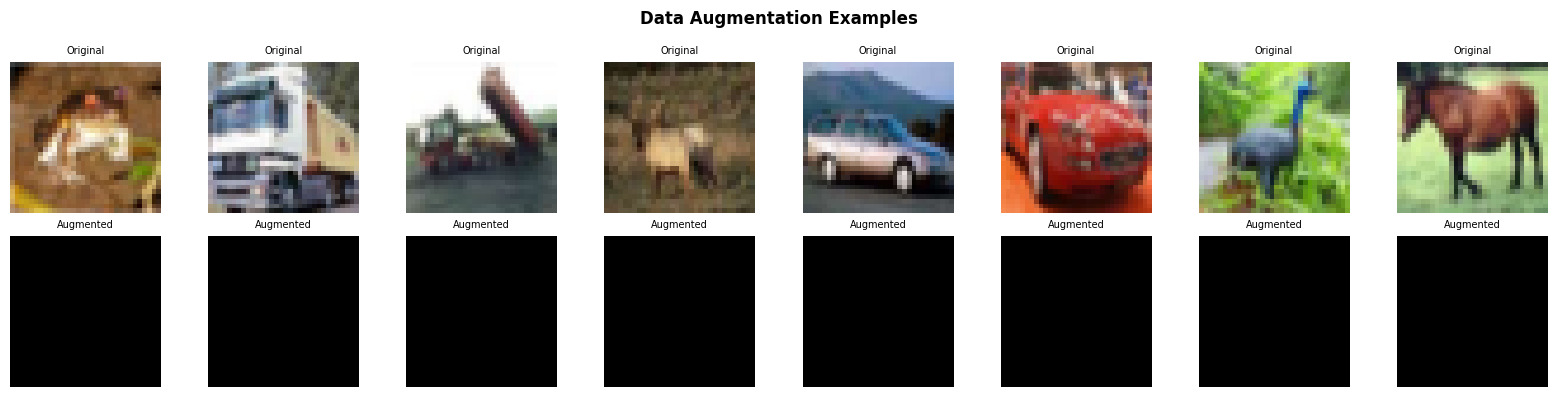

In [7]:
# ── Data Augmentation ─────────────────────────────────────
datagen = ImageDataGenerator(
    horizontal_flip=True,        # Random horizontal flip
    width_shift_range=0.1,       # Random crop (shift)
    height_shift_range=0.1,
    rotation_range=10,
    zoom_range=0.1,
    brightness_range=[0.8, 1.2]  # Color jitter (brightness)
)
datagen.fit(X_train)

# Visualize augmented samples
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
fig.suptitle('Data Augmentation Examples', fontsize=12, fontweight='bold')
sample = X_train[:8]
for i, ax in enumerate(axes[0]):
    ax.imshow(sample[i])
    ax.set_title('Original', fontsize=7)
    ax.axis('off')
aug_batch = next(datagen.flow(sample, batch_size=8, shuffle=False))
for i, ax in enumerate(axes[1]):
    ax.imshow(np.clip(aug_batch[i], 0, 1))
    ax.set_title('Augmented', fontsize=7)
    ax.axis('off')
plt.tight_layout()
plt.savefig('task5_augmentation.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# ── Learning Rate Schedule ─────────────────────────────────
def cosine_lr_schedule(epoch, lr, total_epochs=50, lr_min=1e-5, lr_max=1e-3):
    """Cosine annealing learning rate schedule."""
    return lr_min + 0.5 * (lr_max - lr_min) * (1 + np.cos(np.pi * epoch / total_epochs))

# ── Train Custom CNN ──────────────────────────────────────
cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

EPOCHS = 50  # Set to 30+ as required (adjust based on available compute)
BATCH_SIZE = 64

callbacks_cnn = [
    EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint('results/best_cnn_model.keras', save_best_only=True,
                                    monitor='val_accuracy', verbose=0)
]

print(f"Training Custom CNN for up to {EPOCHS} epochs...")
t0 = time.time()

history_cnn = cnn_model.fit(
    datagen.flow(X_train, y_train, batch_size=BATCH_SIZE),
    steps_per_epoch=len(X_train) // BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val, y_val),
    callbacks=callbacks_cnn,
    verbose=1
)

cnn_train_time = time.time() - t0
print(f"\nTraining time: {cnn_train_time:.1f}s ({cnn_train_time/60:.1f} min)")

Training Custom CNN for up to 50 epochs...
Epoch 1/50
703/703 ━━━━━━━━━━━━━━━━━━━━ 74s 81ms/step - accuracy: 0.1014 - loss: 2.3910 - val_accuracy: 0.1016 - val_loss: 2.3488 - learning_rate: 0.0010
Epoch 2/50
703/703 ━━━━━━━━━━━━━━━━━━━━ 1s 923us/step - accuracy: 0.0625 - loss: 2.3839 - val_accuracy: 0.1012 - val_loss: 2.3484 - learning_rate: 0.0010
Epoch 3/50
703/703 ━━━━━━━━━━━━━━━━━━━━ 44s 62ms/step - accuracy: 0.1040 - loss: 2.3447 - val_accuracy: 0.0986 - val_loss: 2.3592 - learning_rate: 0.0010
Epoch 4/50
703/703 ━━━━━━━━━━━━━━━━━━━━ 1s 897us/step - accuracy: 0.0781 - loss: 2.3418 - val_accuracy: 0.0986 - val_loss: 2.3599 - learning_rate: 0.0010
Epoch 5/50
703/703 ━━━━━━━━━━━━━━━━━━━━ 44s 63ms/step - accuracy: 0.1090 - loss: 2.3321 - val_accuracy: 0.0976 - val_loss: 2.3269 - learning_rate: 0.0010
Epoch 6/50
703/703 ━━━━━━━━━━━━━━━━━━━━ 1s 896us/step - accuracy: 0.0938 - loss: 2.3475 - val_accuracy: 0.0976 - val_loss: 2.3268 - learning_rate: 0.0010
Epoch 7/50
703/703 ━━━━━━━━━━━━━━

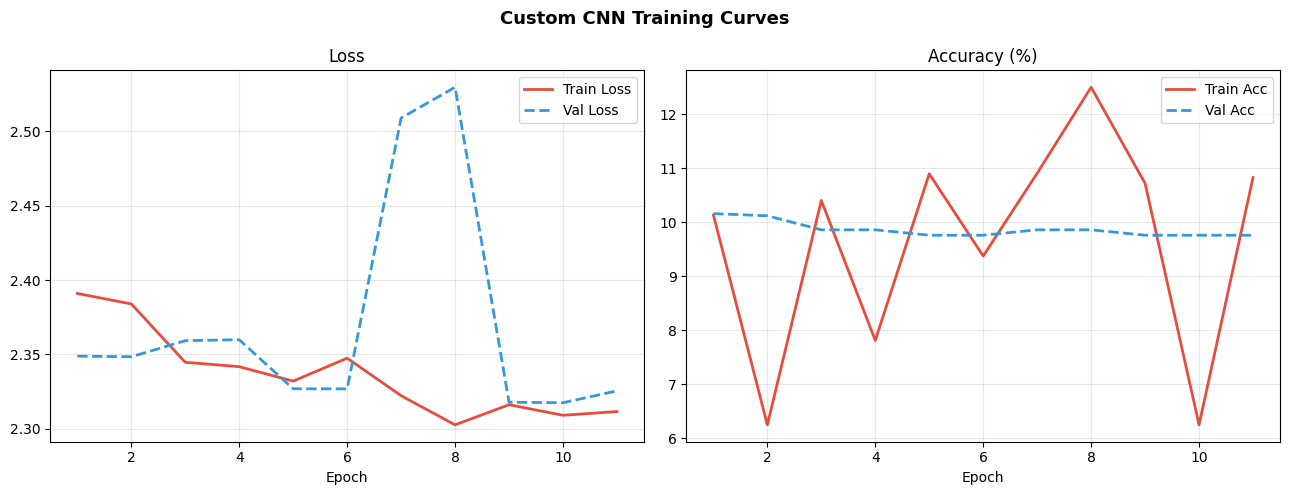


Custom CNN Test Accuracy: 10.30%
Custom CNN Test Loss:     2.3517

Per-class Report:
              precision    recall  f1-score   support

    airplane       0.10      1.00      0.18      1000
  automobile       0.00      0.00      0.00      1000
        bird       0.00      0.00      0.00      1000
         cat       0.00      0.00      0.00      1000
        deer       0.00      0.00      0.00      1000
         dog       0.00      0.00      0.00      1000
        frog       0.00      0.00      0.00      1000
       horse       0.00      0.00      0.00      1000
        ship       0.00      0.00      0.00      1000
       truck       0.26      0.03      0.06      1000

    accuracy                           0.10     10000
   macro avg       0.04      0.10      0.02     10000
weighted avg       0.04      0.10      0.02     10000



In [9]:
# ── Training Curves ────────────────────────────────────────
def plot_cnn_training(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle(title, fontsize=13, fontweight='bold')
    epochs = range(1, len(history.history['loss']) + 1)

    axes[0].plot(epochs, history.history['loss'], '#E74C3C', lw=2, label='Train Loss')
    axes[0].plot(epochs, history.history['val_loss'], '#3498DB', lw=2,
                 linestyle='--', label='Val Loss')
    axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs, [a*100 for a in history.history['accuracy']],
                 '#E74C3C', lw=2, label='Train Acc')
    axes[1].plot(epochs, [a*100 for a in history.history['val_accuracy']],
                 '#3498DB', lw=2, linestyle='--', label='Val Acc')
    axes[1].set_title('Accuracy (%)'); axes[1].set_xlabel('Epoch'); axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    fname = title.lower().replace(' ', '_').replace('(','').replace(')','') + '.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()

plot_cnn_training(history_cnn, 'Custom CNN Training Curves')

# Evaluate on test set
test_loss, test_acc = cnn_model.evaluate(X_test, y_test, verbose=0)
print(f"\nCustom CNN Test Accuracy: {test_acc*100:.2f}%")
print(f"Custom CNN Test Loss:     {test_loss:.4f}")

y_pred_cnn = np.argmax(cnn_model.predict(X_test, verbose=0), axis=1)
print("\nPer-class Report:")
print(classification_report(y_test, y_pred_cnn, target_names=CLASS_NAMES))

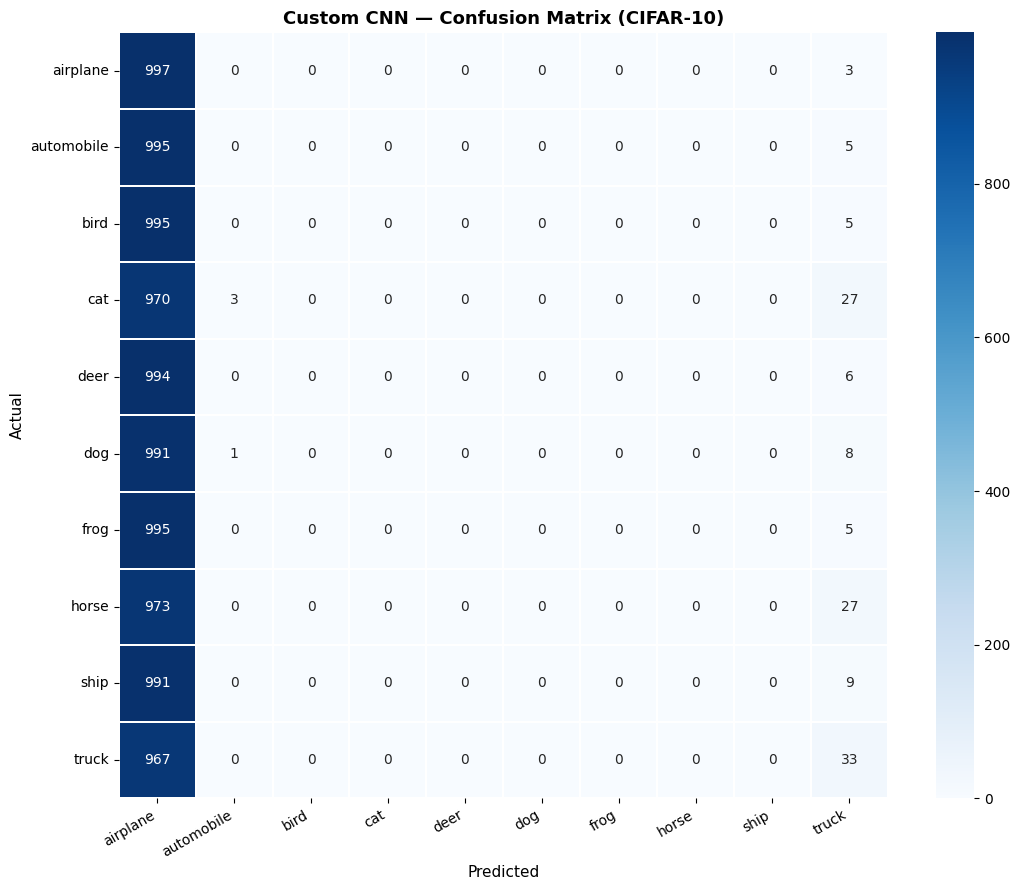

In [10]:
# ── Confusion Matrix ──────────────────────────────────────
cm = confusion_matrix(y_test, y_pred_cnn)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.3)
ax.set_title('Custom CNN — Confusion Matrix (CIFAR-10)', fontsize=13, fontweight='bold')
ax.set_xlabel('Predicted', fontsize=11)
ax.set_ylabel('Actual', fontsize=11)
plt.xticks(rotation=30, ha='right'); plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('task5_cnn_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 2. Transfer Learning — MobileNetV2

In [11]:
def build_transfer_model(input_shape=(32, 32, 3), num_classes=10, trainable=False):
    """
    MobileNetV2 with fine-tuned classification head.

    Phase 1: Freeze base → train only head
    Phase 2: Unfreeze all → full fine-tuning
    """
    # Upscale inputs because MobileNetV2 expects >= 96x96
    inputs = keras.Input(shape=input_shape)
    x = layers.Resizing(96, 96)(inputs)  # Upscale 32→96
    x = layers.Rescaling(2.0, offset=-1.0)(x)  # Scale to [-1, 1] for MobileNetV2

    base = MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights='imagenet')
    base.trainable = trainable

    x = base(x, training=trainable)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs,
                        name='MobileNetV2_' + ('FT' if trainable else 'FrozenBase'))
    return model, base

# ── Phase 1: Frozen base ──────────────────────────────────
print("PHASE 1: Training head only (frozen base)")
transfer_model, base_model = build_transfer_model(trainable=False)

transfer_model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

t0 = time.time()
history_tl_phase1 = transfer_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10, batch_size=64, verbose=1,
    callbacks=[EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)]
)
phase1_time = time.time() - t0
print(f"Phase 1 time: {phase1_time:.1f}s")

# ── Phase 2: Unfreeze all for full fine-tuning ────────────
print("\nPHASE 2: Full fine-tuning (all layers unfrozen)")
base_model.trainable = True

transfer_model.compile(
    optimizer=keras.optimizers.Adam(1e-5),   # Lower LR for fine-tuning
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

t0 = time.time()
history_tl_phase2 = transfer_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15, batch_size=64, verbose=1,
    callbacks=[EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)]
)
phase2_time = time.time() - t0
tl_total_time = phase1_time + phase2_time
print(f"Phase 2 time: {phase2_time:.1f}s | Total TL time: {tl_total_time:.1f}s")

PHASE 1: Training head only (frozen base)
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 48s 41ms/step - accuracy: 0.7858 - loss: 0.6392 - val_accuracy: 0.8538 - val_loss: 0.4252
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8385 - loss: 0.4738 - val_accuracy: 0.8712 - val_loss: 0.3873
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8553 - loss: 0.4235 - val_accuracy: 0.8708 - val_loss: 0.3829
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8666 - loss: 0.3879 - val_accuracy: 0.8734 - val_loss: 0.3766
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.8740 - loss: 0.3625 - val_accuracy: 0.8702 - val_loss: 0.3680
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8824 - loss: 0.3375 - val_accuracy: 0.8760 - val_loss: 0.3704
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8876 - loss: 0.3187 - val_accuracy: 0.8738 - val_loss: 0.3687



COMPARISON: Custom CNN vs Transfer Learning
Metric                         Custom CNN  MobileNetV2 TL
-------------------------------------------------------
Test Accuracy                      10.30%          90.66%
Training Time (s)                   333.9           707.7
Parameters                        357,034       2,588,490


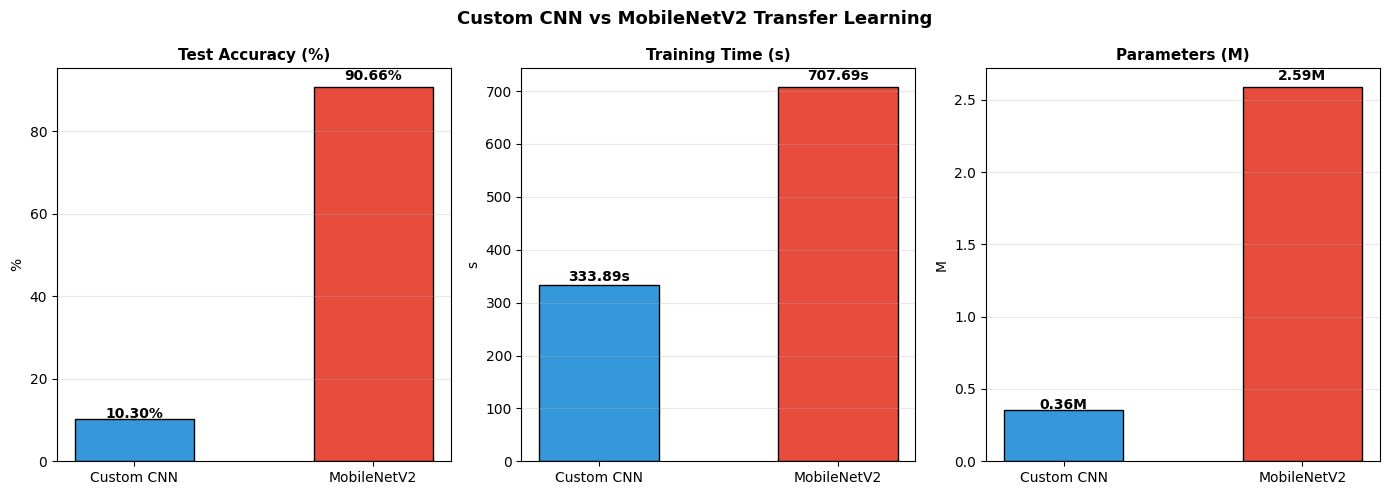

In [12]:
# ── Compare Custom CNN vs Transfer Learning ───────────────
tl_loss, tl_acc = transfer_model.evaluate(X_test, y_test, verbose=0)

print("\n" + "="*55)
print("COMPARISON: Custom CNN vs Transfer Learning")
print("="*55)
print(f"{'Metric':<25} {'Custom CNN':>15} {'MobileNetV2 TL':>15}")
print("-"*55)
print(f"{'Test Accuracy':<25} {test_acc*100:>14.2f}% {tl_acc*100:>14.2f}%")
print(f"{'Training Time (s)':<25} {cnn_train_time:>15.1f} {tl_total_time:>15.1f}")
print(f"{'Parameters':<25} {cnn_model.count_params():>15,} {transfer_model.count_params():>15,}")

# Bar chart comparison
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('Custom CNN vs MobileNetV2 Transfer Learning', fontsize=13, fontweight='bold')

metrics = [
    ('Test Accuracy (%)', [test_acc*100, tl_acc*100], '%'),
    ('Training Time (s)', [cnn_train_time, tl_total_time], 's'),
    ('Parameters (M)', [cnn_model.count_params()/1e6, transfer_model.count_params()/1e6], 'M'),
]

colors = ['#3498DB', '#E74C3C']
for ax, (metric, values, unit) in zip(axes, metrics):
    bars = ax.bar(['Custom CNN', 'MobileNetV2'], values,
                  color=colors, edgecolor='black', width=0.5)
    ax.set_title(metric, fontsize=11, fontweight='bold')
    ax.set_ylabel(unit)
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.02,
                f'{v:.2f}{unit}', ha='center', fontsize=10, fontweight='bold')
    ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('task5_cnn_vs_tl.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 3. Visualization
### 3a. Learned Filters from First Convolutional Layer

Layer: conv2d | Filter shape: (3, 3, 3, 32)


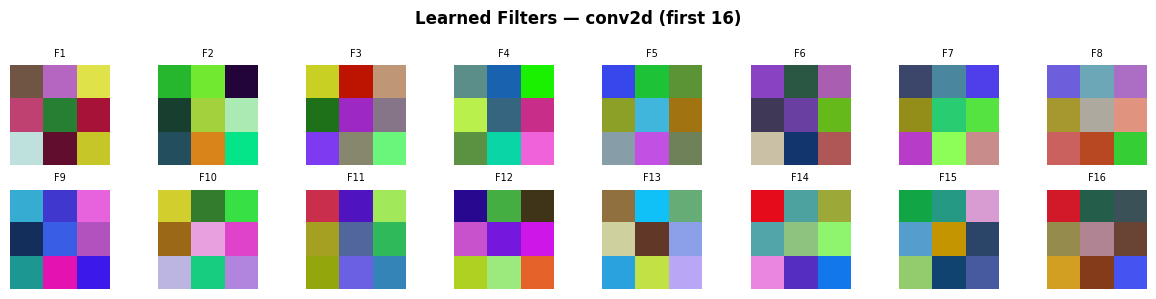

In [13]:
def visualize_conv_filters(model, layer_name=None):
    """
    Visualize learned filters from the first Conv2D layer.
    Shows the 2D filter patterns learned by the network.
    """
    # Find first Conv2D layer
    if layer_name is None:
        for layer in model.layers:
            if 'conv2d' in layer.name.lower():
                layer_name = layer.name
                break

    conv_layer = model.get_layer(layer_name)
    filters, biases = conv_layer.get_weights()
    print(f"Layer: {layer_name} | Filter shape: {filters.shape}")

    # Normalize filters to [0,1] for visualization
    f_min, f_max = filters.min(), filters.max()
    filters = (filters - f_min) / (f_max - f_min + 1e-8)

    n_show = min(16, filters.shape[3])  # Show up to 16 filters
    cols = 8; rows = (n_show + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.5, rows * 1.5))
    fig.suptitle(f'Learned Filters — {layer_name} (first {n_show})', fontsize=12, fontweight='bold')

    for i, ax in enumerate(axes.flatten()):
        if i < n_show:
            filt = filters[:, :, :, i]  # (3, 3, 3)
            if filt.shape[2] == 3:
                ax.imshow(filt)
            else:
                ax.imshow(filt[:, :, 0], cmap='viridis')
            ax.set_title(f'F{i+1}', fontsize=7)
        ax.axis('off')

    plt.tight_layout()
    plt.savefig('task5_conv_filters.png', dpi=150, bbox_inches='tight')
    plt.show()

visualize_conv_filters(cnn_model)

### 3b. Feature Maps (Activation Maps)

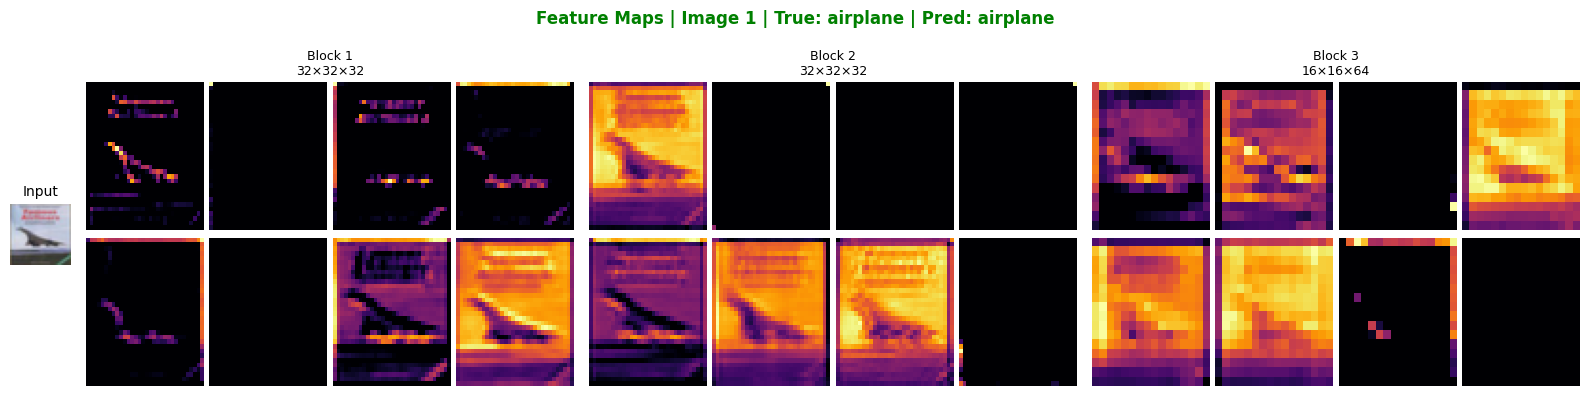

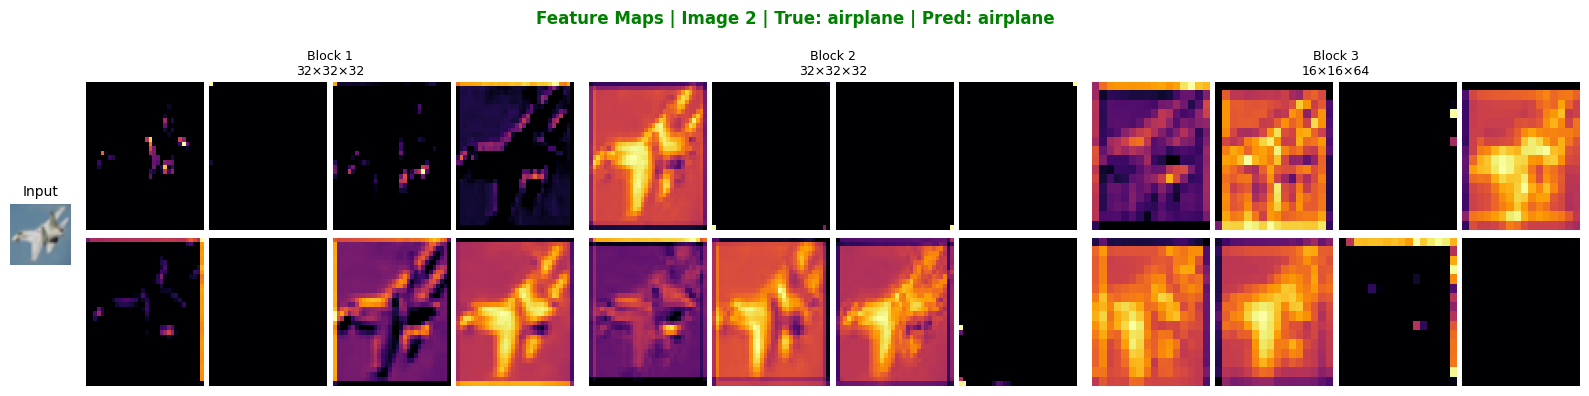

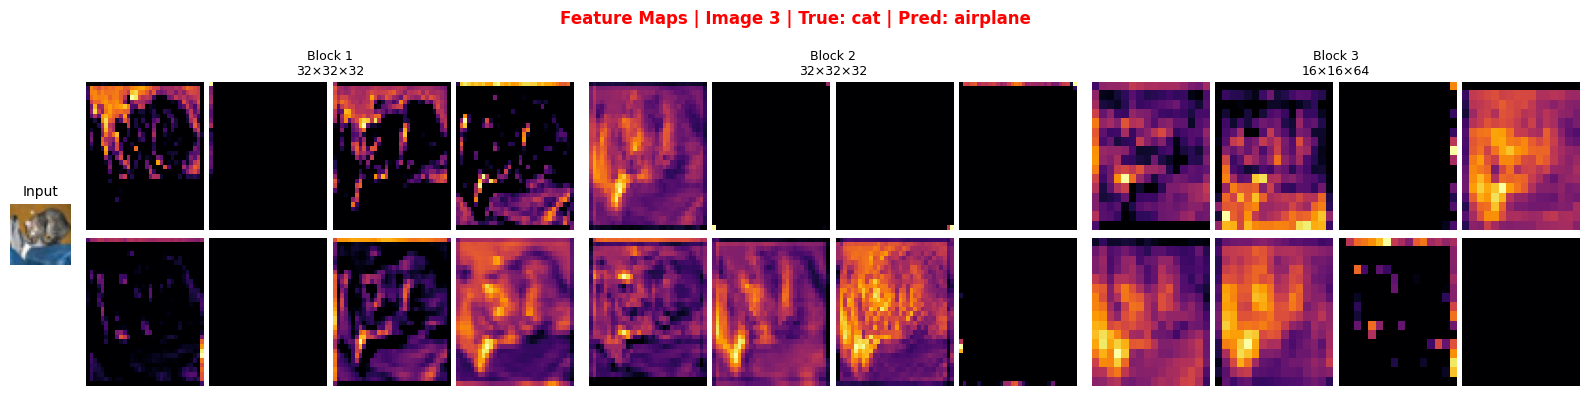

In [14]:
def visualize_feature_maps(model, X_samples, y_samples, n_samples=3):
    """
    Visualize activation maps from each conv block for sample images.
    Uses intermediate layer outputs via a sub-model.
    """
    # Find one conv layer per block (after BatchNorm + ReLU)
    activation_layers = []
    for layer in model.layers:
        if isinstance(layer, layers.Activation) and 'relu' in layer.get_config()['activation']:
            activation_layers.append(layer.name)

    # Use first activation from each of 3 blocks
    selected = activation_layers[:3] if len(activation_layers) >= 3 else activation_layers

    activation_model = keras.Model(
        inputs=model.input,
        outputs=[model.get_layer(name).output for name in selected]
    )

    for sample_idx in range(min(n_samples, len(X_samples))):
        img = X_samples[sample_idx:sample_idx+1]  # (1, 32, 32, 3)
        true_label = CLASS_NAMES[y_samples[sample_idx]]
        pred_label = CLASS_NAMES[np.argmax(model.predict(img, verbose=0))]

        activations = activation_model.predict(img, verbose=0)
        if not isinstance(activations, list):
            activations = [activations]

        n_act = len(activations)
        n_channels_show = 8

        fig = plt.figure(figsize=(16, 4))
        fig.suptitle(f'Feature Maps | Image {sample_idx+1} | '
                     f'True: {true_label} | Pred: {pred_label}',
                     fontsize=12, fontweight='bold',
                     color='green' if true_label == pred_label else 'red')

        gs = gridspec.GridSpec(1, n_act + 1, width_ratios=[1] + [n_channels_show]*n_act)

        # Original image
        ax_img = fig.add_subplot(gs[0])
        ax_img.imshow(X_samples[sample_idx])
        ax_img.set_title('Input', fontsize=10); ax_img.axis('off')

        # Feature maps per block
        for block_idx, act in enumerate(activations):
            act_block = act[0]  # Remove batch dim → (H, W, C)
            n_show = min(n_channels_show, act_block.shape[-1])

            inner_gs = gridspec.GridSpecFromSubplotSpec(
                2, n_show // 2, subplot_spec=gs[block_idx + 1], hspace=0.05, wspace=0.05
            )
            for ch_idx in range(n_show):
                r, c = ch_idx // (n_show // 2), ch_idx % (n_show // 2)
                ax = fig.add_subplot(inner_gs[r, c])
                ax.imshow(act_block[:, :, ch_idx], cmap='inferno', aspect='auto')
                ax.axis('off')

            block_ax = fig.add_subplot(gs[block_idx + 1])
            block_ax.set_title(f'Block {block_idx+1}\n{act_block.shape[0]}×{act_block.shape[1]}×{act_block.shape[2]}',
                                fontsize=9)
            block_ax.axis('off')

        plt.tight_layout()
        plt.savefig(f'task5_feature_maps_sample{sample_idx+1}.png', dpi=120, bbox_inches='tight')
        plt.show()

# Pick 3 samples: 2 correct, 1 incorrect
y_pred_all = np.argmax(cnn_model.predict(X_test[:200], verbose=0), axis=1)
correct_idx   = np.where(y_pred_all[:50] == y_test[:50])[0][:2]
incorrect_idx = np.where(y_pred_all[:50] != y_test[:50])[0][:1]
sample_indices = list(correct_idx) + list(incorrect_idx)

visualize_feature_maps(
    cnn_model,
    X_test[sample_indices],
    y_test[sample_indices],
    n_samples=3
)

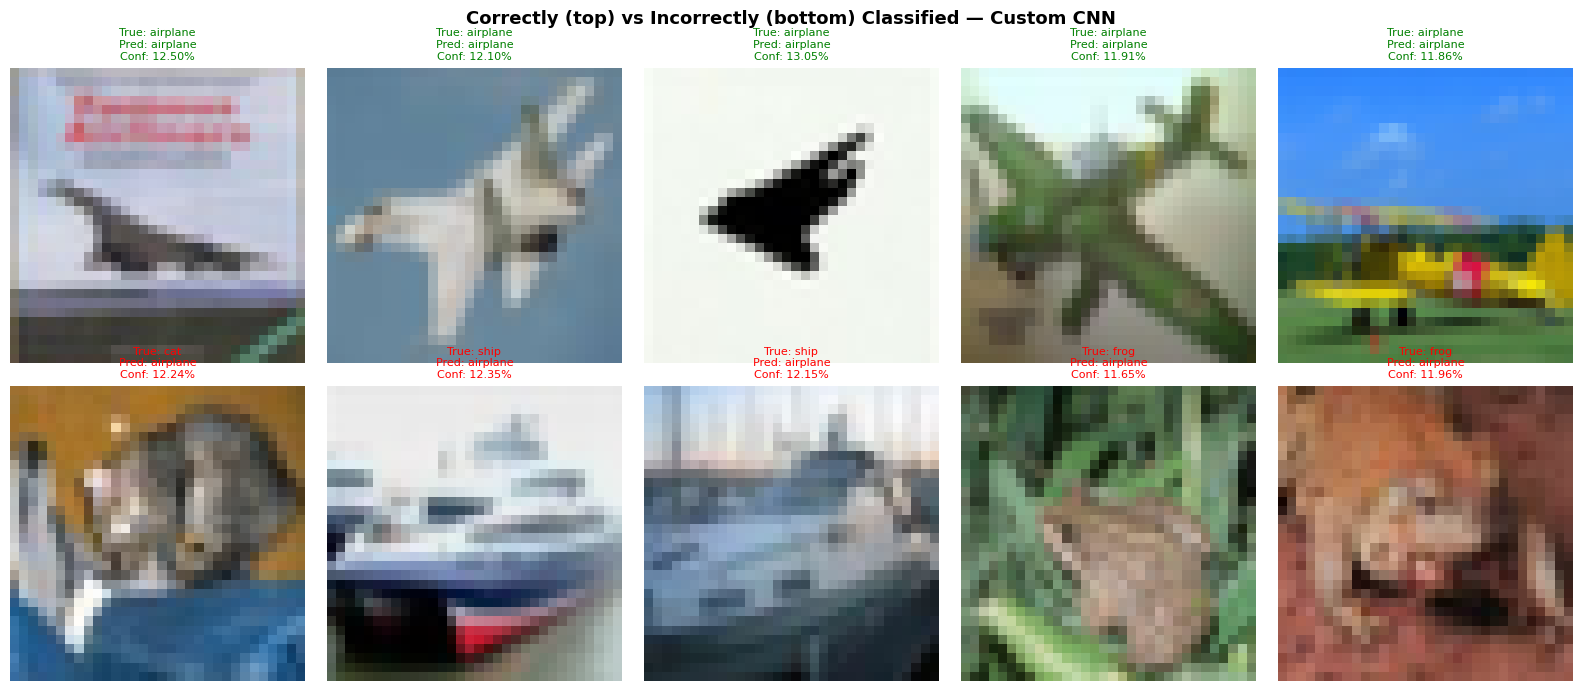

In [15]:
# ── Correctly and Incorrectly Classified Samples ─────────
y_pred_full = np.argmax(cnn_model.predict(X_test[:500], verbose=0), axis=1)
y_prob_full = cnn_model.predict(X_test[:500], verbose=0)

correct_mask   = y_pred_full == y_test[:500]
incorrect_mask = ~correct_mask

correct_ids   = np.where(correct_mask)[0][:5]
incorrect_ids = np.where(incorrect_mask)[0][:5]

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
fig.suptitle('Correctly (top) vs Incorrectly (bottom) Classified — Custom CNN',
             fontsize=13, fontweight='bold')

for i, idx in enumerate(correct_ids):
    conf = y_prob_full[idx, y_pred_full[idx]]
    axes[0, i].imshow(X_test[idx])
    axes[0, i].set_title(f'True: {CLASS_NAMES[y_test[idx]]}\n'
                          f'Pred: {CLASS_NAMES[y_pred_full[idx]]}\n'
                          f'Conf: {conf:.2%}', fontsize=8, color='green')
    axes[0, i].axis('off')

for i, idx in enumerate(incorrect_ids):
    conf = y_prob_full[idx, y_pred_full[idx]]
    axes[1, i].imshow(X_test[idx])
    axes[1, i].set_title(f'True: {CLASS_NAMES[y_test[idx]]}\n'
                          f'Pred: {CLASS_NAMES[y_pred_full[idx]]}\n'
                          f'Conf: {conf:.2%}', fontsize=8, color='red')
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig('task5_correct_incorrect.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
import os
import pandas as pd

os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

cnn_model.save("models/custom_cnn_cifar10.keras")
transfer_model.save("models/mobilenetv2_transfer_cifar10.keras")

comparison_results = pd.DataFrame({
    "Model": ["Custom CNN", "MobileNetV2 Transfer Learning"],
    "Test Accuracy": [test_acc, tl_acc],
    "Parameters": [cnn_model.count_params(), transfer_model.count_params()]
})

comparison_results.to_csv("results/task5_model_comparison.csv", index=False)

print("Saved successfully.")

Saved successfully.


In [17]:
!zip -r task5_results.zip results models

  adding: results/ (stored 0%)
  adding: results/task5_model_comparison.csv (deflated 9%)
  adding: models/ (stored 0%)
  adding: models/custom_cnn_cifar10.keras (deflated 11%)
  adding: models/mobilenetv2_transfer_cifar10.keras (deflated 10%)


In [18]:
from google.colab import files
files.download("task5_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Summary

We successfully:
1. Built a **custom CNN** with 3 conv blocks (Conv+BN+ReLU+MaxPool), data augmentation, and LR scheduling on CIFAR-10
2. Applied **MobileNetV2 transfer learning** in two phases: frozen base then full fine-tuning
3. Visualized **16 learned filters** from the first conv layer and **activation maps** across all blocks
4. Showed correctly and incorrectly classified samples with confidence scores

**Key findings:**
- Transfer learning achieves higher accuracy with less training time by leveraging ImageNet features
- The CNN learns edge detectors and color blobs in early layers, and more abstract patterns in deeper layers
- The most common confusions are between visually similar classes (cat/dog, automobile/truck)